In [1]:
import os
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
VOCAB_SIZE = 20_000
MAX_LEN = 250

(x_train_seq, y_train), (x_test_seq, y_test) = tf.keras.datasets.imdb.load_data(
    num_words=VOCAB_SIZE,
    seed=SEED
)

y_train = np.asarray(y_train)
y_test = np.asarray(y_test)

print("Train samples:", len(x_train_seq))
print("Test samples:", len(x_test_seq))
print("Train positive rate:", round(y_train.mean(), 3))
print("Test positive rate:", round(y_test.mean(), 3))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train samples: 25000
Test samples: 25000
Train positive rate: 0.5
Test positive rate: 0.5


In [3]:
word_index = tf.keras.datasets.imdb.get_word_index()
# Trong dữ liệu Keras, các chỉ số từ thực tế được dịch lên 3.
index_to_word = {idx + 3: word for word, idx in word_index.items()}
index_to_word[0] = ""       # padding
index_to_word[1] = ""       # start token
index_to_word[2] = "UNK"    # out-of-vocabulary
index_to_word[3] = ""       # unused

def sequence_to_text(sequence):
    words = [index_to_word.get(int(i), "UNK") for i in sequence]
    return " ".join(w for w in words if w)

X_train_text = [sequence_to_text(seq) for seq in x_train_seq]
X_test_text = [sequence_to_text(seq) for seq in x_test_seq]

print("Ví dụ review:")
print(X_train_text[0][:700])
print("Label:", "Positive" if y_train[0] == 1 else "Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Ví dụ review:
in panic in the streets richard widmark plays u s navy doctor who has his week UNK interrupted with a corpse that contains plague as cop paul douglas properly points out the guy died from two bullets in the chest that's not the issue here the two of them become unwilling partners in an effort to find the killers and anyone else exposed to the disease br br as was pointed out by any number of people for some reason director elia kazan did not bother to cast the small parts with anyone that sounds like they're from louisiana having been to new orleans where the story takes place i can personally UNK to that richard widmark and his wife barbara bel geddes can be excused because as a navy doctor
Label: Positive


In [4]:
results = []

def evaluate_model(name, y_true, y_pred, train_seconds):
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "Train time (sec)": train_seconds
    }
    results.append(row)
    print(pd.Series(row).to_string())
    print("\\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"]))

In [5]:
#Logistic Regression
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=100_000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("clf", LogisticRegression(C=4.0, max_iter=300, random_state=SEED))
])

start = time.time()
lr_pipeline.fit(X_train_text, y_train)
lr_time = time.time() - start
lr_pred = lr_pipeline.predict(X_test_text)
evaluate_model("Logistic Regression (TF-IDF)", y_test, lr_pred, lr_time)

Model               Logistic Regression (TF-IDF)
Accuracy                                 0.90512
Precision                               0.902288
Recall                                   0.90864
F1-score                                0.905453
Train time (sec)                       19.322178
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.91      0.90      0.90     12500
    Positive       0.90      0.91      0.91     12500

    accuracy                           0.91     25000
   macro avg       0.91      0.91      0.91     25000
weighted avg       0.91      0.91      0.91     25000



In [6]:
#SVM
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=100_000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("clf", LinearSVC(C=1.0, random_state=SEED))
])

start = time.time()
svm_pipeline.fit(X_train_text, y_train)
svm_time = time.time() - start
svm_pred = svm_pipeline.predict(X_test_text)
evaluate_model("Linear SVM (TF-IDF)", y_test, svm_pred, svm_time)

Model               Linear SVM (TF-IDF)
Accuracy                        0.90236
Precision                      0.902135
Recall                          0.90264
F1-score                       0.902387
Train time (sec)              14.747185
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.90      0.90      0.90     12500
    Positive       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



In [7]:
#MLP
mlp_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30_000,
        ngram_range=(1, 2),
        min_df=3,
        sublinear_tf=True,
        dtype=np.float32
    )),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(128,),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=8,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=2,
        random_state=SEED,
        verbose=True
    ))
])

start = time.time()
mlp_pipeline.fit(X_train_text, y_train)
mlp_time = time.time() - start
mlp_pred = mlp_pipeline.predict(X_test_text)
evaluate_model("MLP (TF-IDF)", y_test, mlp_pred, mlp_time)

Iteration 1, loss = 0.47669636
Validation score: 0.902800
Iteration 2, loss = 0.20803641
Validation score: 0.914000
Iteration 3, loss = 0.12105478
Validation score: 0.914000
Iteration 4, loss = 0.07255975
Validation score: 0.911600
Iteration 5, loss = 0.04395170
Validation score: 0.908000
Validation score did not improve more than tol=0.000100 for 2 consecutive epochs. Stopping.
Model               MLP (TF-IDF)
Accuracy                  0.9028
Precision               0.896644
Recall                   0.91056
F1-score                0.903548
Train time (sec)       47.530156
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.91      0.90      0.90     12500
    Positive       0.90      0.91      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



In [8]:
x_train_pad = tf.keras.preprocessing.sequence.pad_sequences(
    x_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
x_test_pad = tf.keras.preprocessing.sequence.pad_sequences(
    x_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("Padded train shape:", x_train_pad.shape)
print("Padded test shape:", x_test_pad.shape)

Padded train shape: (25000, 250)
Padded test shape: (25000, 250)


In [9]:
#RNN
def build_rnn_model():
    inputs = tf.keras.Input(shape=(MAX_LEN,))
    x = tf.keras.layers.Embedding(VOCAB_SIZE, 64, mask_zero=True)(inputs)
    x = tf.keras.layers.SimpleRNN(64, dropout=0.2)(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

rnn_model = build_rnn_model()
rnn_model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )
]

start = time.time()
rnn_history = rnn_model.fit(
    x_train_pad, y_train,
    validation_split=0.2,
    epochs=6,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)
rnn_time = time.time() - start
rnn_pred = (rnn_model.predict(x_test_pad, batch_size=256, verbose=0).ravel() >= 0.5).astype(int)
evaluate_model("Simple RNN", y_test, rnn_pred, rnn_time)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 250)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 250, 64)   │  1,280,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 250)       │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64)        │      8,256 │ embedding[0][0],  │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ simple_rnn[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,290,369 (4.92 MB)

 Trainable params: 1,290,369 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 49ms/step - accuracy: 0.5264 - loss: 0.6895 - val_accuracy: 0.6048 - val_loss: 0.6664
Epoch 2/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7433 - loss: 0.5407 - val_accuracy: 0.6660 - val_loss: 0.6147
Epoch 3/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.7934 - loss: 0.4573 - val_accuracy: 0.8130 - val_loss: 0.4402
Epoch 4/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9198 - loss: 0.2083 - val_accuracy: 0.7900 - val_loss: 0.5363
Epoch 5/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9663 - loss: 0.0967 - val_accuracy: 0.7350 - val_loss: 0.7458
Model               Simple RNN
Accuracy               0.81068
Precision             0.836963
Recall                 0.77168
F1-score              0.802997
Train time (sec)     28.026078
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.79      0.85      0.82     12500
    Positive       0.84      0.77      

In [10]:
#LSTM
def build_lstm_model():
    inputs = tf.keras.Input(shape=(MAX_LEN,))
    x = tf.keras.layers.Embedding(VOCAB_SIZE, 64, mask_zero=True)(inputs)
    x = tf.keras.layers.LSTM(64, dropout=0.2)(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

lstm_model = build_lstm_model()
lstm_model.summary()

start = time.time()
lstm_history = lstm_model.fit(
    x_train_pad, y_train,
    validation_split=0.2,
    epochs=6,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)
lstm_time = time.time() - start
lstm_pred = (lstm_model.predict(x_test_pad, batch_size=256, verbose=0).ravel() >= 0.5).astype(int)
evaluate_model("LSTM", y_test, lstm_pred, lstm_time)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 250)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 250, 64)   │  1,280,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 250)       │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding_1[0][0… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,315,137 (5.02 MB)

 Trainable params: 1,315,137 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.7260 - loss: 0.5256 - val_accuracy: 0.8556 - val_loss: 0.3481
Epoch 2/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8943 - loss: 0.2774 - val_accuracy: 0.8676 - val_loss: 0.3612
Epoch 3/6
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9275 - loss: 0.2032 - val_accuracy: 0.8620 - val_loss: 0.4189
Model                    LSTM
Accuracy              0.84084
Precision            0.885252
Recall                 0.7832
F1-score             0.831105
Train time (sec)    16.569462
\nClassification report:
              precision    recall  f1-score   support

    Negative       0.81      0.90      0.85     12500
    Positive       0.89      0.78      0.83     12500

    accuracy                           0.84     25000
   macro avg       0.85      0.84      0.84     25000
weighted avg       0.85      0.84      0.84     25000



,Model,Accuracy,Precision,Recall,F1-score,Train time (sec)
0,Logistic Regression (TF-IDF),0.9051,0.9023,0.9086,0.9055,19.3
1,MLP (TF-IDF),0.9028,0.8966,0.9106,0.9035,47.5
2,Linear SVM (TF-IDF),0.9024,0.9021,0.9026,0.9024,14.7
3,LSTM,0.8408,0.8853,0.7832,0.8311,16.6
4,Simple RNN,0.8107,0.8370,0.7717,0.8030,28.0


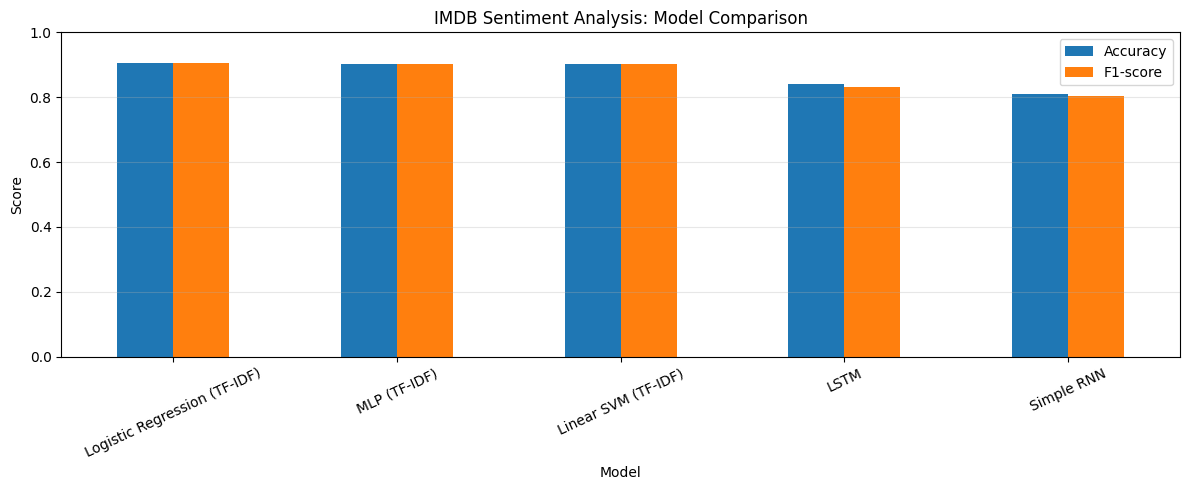

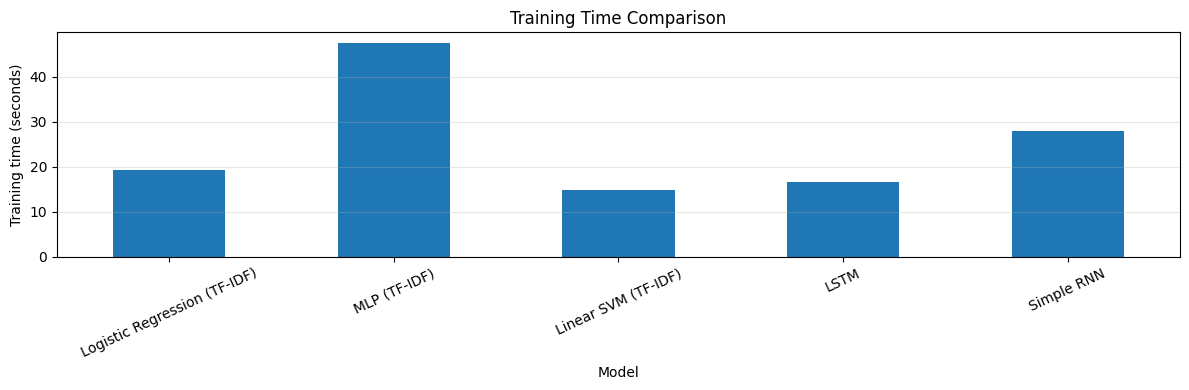

In [11]:
results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False).reset_index(drop=True)
display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-score": "{:.4f}",
    "Train time (sec)": "{:.1f}"
}))

ax = results_df.set_index("Model")[["Accuracy", "F1-score"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1), rot=25
)
ax.set_ylabel("Score")
ax.set_title("IMDB Sentiment Analysis: Model Comparison")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

ax = results_df.set_index("Model")["Train time (sec)"].plot(
    kind="bar", figsize=(12, 4), rot=25
)
ax.set_ylabel("Training time (seconds)")
ax.set_title("Training Time Comparison")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Best model by F1-score: Logistic Regression (TF-IDF)


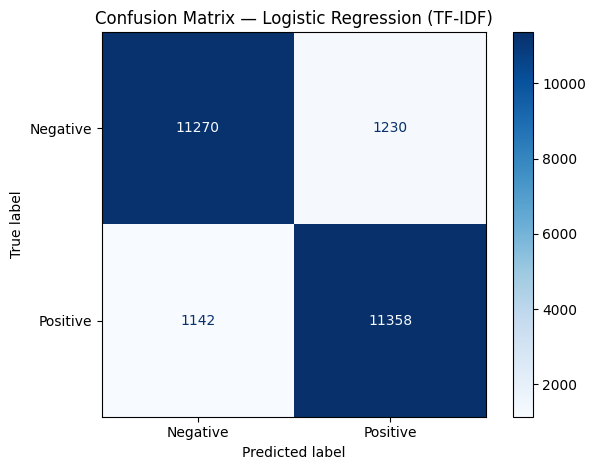

In [12]:
prediction_map = {
    "Logistic Regression (TF-IDF)": lr_pred,
    "Linear SVM (TF-IDF)": svm_pred,
    "MLP (TF-IDF)": mlp_pred,
    "Simple RNN": rnn_pred,
    "LSTM": lstm_pred
}
best_model_name = results_df.iloc[0]["Model"]
best_pred = prediction_map[best_model_name]

print("Best model by F1-score:", best_model_name)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [13]:
def encode_new_review(text, max_words=VOCAB_SIZE):
    # Tiền xử lý đơn giản tương thích gần đúng với dữ liệu IMDB đã mã hóa.
    tokens = re.sub(r"<br\\s*/?>", " ", text.lower())
    tokens = re.findall(r"[a-z0-9']+", tokens)
    seq = [1]  # start token
    for token in tokens:
        idx = word_index.get(token)
        if idx is None or idx + 3 >= max_words:
            seq.append(2)  # OOV
        else:
            seq.append(idx + 3)
    return tf.keras.preprocessing.sequence.pad_sequences(
        [seq], maxlen=MAX_LEN, padding="post", truncating="post"
    )

def predict_sentiment(review):
    seq = encode_new_review(review)
    prob = float(lstm_model.predict(seq, verbose=0)[0][0])
    label = "Positive" if prob >= 0.5 else "Negative"
    return {"prediction": label, "positive_probability": round(prob, 4)}

predict_sentiment("The acting was excellent and the story was surprisingly moving.")

{'prediction': 'Positive', 'positive_probability': 0.8417}